# Side-Channel Attack on Masked AES-128 with Deep Learning
### ASCAD v1 (fixed key): leakage analysis, CPA, MLP and CNN attacks, guessing entropy

This notebook tests how well a masked AES-128 implementation resists side-channel attacks. It starts with classical leakage analysis and a correlation attack, then trains two neural networks (an MLP and a 1D CNN) to recover a key byte, and finally checks how much simulated clock jitter and added noise slow the attack down.

**Attack setting.** The attacker has a clone device where plaintext, key and masks are known, and uses it to record profiling traces. The attacker then targets a second device with the same kind of implementation, where the key and the masks are unknown. The question is how many traces are needed to recover the key.

**Dataset.** ASCAD v1 fixed-key (`ASCAD.h5`): electromagnetic traces from a software-masked AES-128 on an 8-bit ATmega8515 microcontroller. The target is the S-box output for key byte 2 in the first round. It has 50,000 profiling traces, 10,000 attack traces and 700 samples per trace.

**Metrics.** Results are judged with SNR, a t-test, CPA correlation, guessing entropy and minimum traces to disclosure (MTD). Plain classification accuracy is shown for reference only, because it says very little about whether a key can be recovered.

In [19]:
# Imports and settings
import os, glob, math, json
import numpy as np
import h5py
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 1
np.random.seed(SEED)
tf.random.set_seed(SEED)

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True

## 0. Load the ASCAD file

The next cell looks for the ASCAD fixed-key file in the usual Kaggle folders. It skips the `desync` and `variable` versions of the dataset. If the file is not found automatically, set `ASCAD_PATH` by hand.

In [20]:
# Find the ASCAD file
def find_ascad_file():
    candidates = []
    for root in ["/kaggle/input", "/kaggle/working", "."]:
        if os.path.isdir(root):
            candidates += glob.glob(os.path.join(root, "**", "*.h5"), recursive=True)
    scored = []
    for c in candidates:
        name = os.path.basename(c).lower()
        if "ascad" not in name and "ascad" not in c.lower():
            continue
        score = 0
        if "desync" in name: score -= 5
        if "variable" in name: score -= 5
        if name == "ascad.h5": score += 10
        scored.append((score, c))
    scored.sort(reverse=True)
    return scored[0][1] if scored else (candidates[0] if candidates else None)

ASCAD_PATH = find_ascad_file()
print("Auto-detected ASCAD file:", ASCAD_PATH)
assert ASCAD_PATH is not None, "Could not find an .h5 file under /kaggle/input. Set ASCAD_PATH manually."

Auto-detected ASCAD file: /kaggle/input/datasets/awasim/ascad-v1-fixed-key-aes-side-channel-dataset/ASCAD.h5


In [21]:
# Load the data
TARGET_BYTE = 2

def load_ascad(path):
    with h5py.File(path, "r") as f:
        print("Top-level groups:", list(f.keys()))
        prof_g, atk_g = f["Profiling_traces"], f["Attack_traces"]
        print("Profiling fields:", list(prof_g.keys()), " metadata fields:", prof_g["metadata"].dtype.names)

        data = {
            "X_profile": np.asarray(prof_g["traces"], dtype=np.float32),
            "y_profile": np.asarray(prof_g["labels"], dtype=np.int64) if "labels" in prof_g else None,
            "pt_profile": np.asarray(prof_g["metadata"]["plaintext"], dtype=np.uint8),
            "key_profile": np.asarray(prof_g["metadata"]["key"], dtype=np.uint8),
            "X_attack": np.asarray(atk_g["traces"], dtype=np.float32),
            "y_attack": np.asarray(atk_g["labels"], dtype=np.int64) if "labels" in atk_g else None,
            "pt_attack": np.asarray(atk_g["metadata"]["plaintext"], dtype=np.uint8),
            "key_attack": np.asarray(atk_g["metadata"]["key"], dtype=np.uint8),
        }
        for split, g in [("profile", prof_g), ("attack", atk_g)]:
            names = g["metadata"].dtype.names
            data[f"masks_{split}"] = np.asarray(g["metadata"]["masks"], dtype=np.uint8) if "masks" in names else None
    return data

D = load_ascad(ASCAD_PATH)
X_profile, X_attack = D["X_profile"], D["X_attack"]
print("Profiling traces:", X_profile.shape, " Attack traces:", X_attack.shape)

ATTACK_KEY_BYTE = int(D["key_attack"][0, TARGET_BYTE])
print("True (ground-truth, evaluation-only) attack-device key byte:", hex(ATTACK_KEY_BYTE))

Top-level groups: ['Attack_traces', 'Profiling_traces']
Profiling fields: ['labels', 'metadata', 'traces']  metadata fields: ('plaintext', 'ciphertext', 'key', 'masks', 'desync')
Profiling traces: (50000, 700)  Attack traces: (10000, 700)
True (ground-truth, evaluation-only) attack-device key byte: 0xe0


## 1. Where does the device leak? (SNR and TVLA)

Before attacking anything, it helps to know at which point in time the device leaks, and what kind of leakage it is. Two questions are checked:

* Does the plain S-box output leak at any single time sample? If the masking works, it should not, and the SNR should stay at noise level everywhere.
* Does the masked S-box output leak? It should, because the device has to handle that value. The SNR should show a clear peak at that moment.

The gap between the two plots shows that the masking is doing its job at first order, and it tells us which time sample matters.

In [22]:
# AES S-box and Hamming weight table
AES_SBOX = np.array([
0x63,0x7c,0x77,0x7b,0xf2,0x6b,0x6f,0xc5,0x30,0x01,0x67,0x2b,0xfe,0xd7,0xab,0x76,
0xca,0x82,0xc9,0x7d,0xfa,0x59,0x47,0xf0,0xad,0xd4,0xa2,0xaf,0x9c,0xa4,0x72,0xc0,
0xb7,0xfd,0x93,0x26,0x36,0x3f,0xf7,0xcc,0x34,0xa5,0xe5,0xf1,0x71,0xd8,0x31,0x15,
0x04,0xc7,0x23,0xc3,0x18,0x96,0x05,0x9a,0x07,0x12,0x80,0xe2,0xeb,0x27,0xb2,0x75,
0x09,0x83,0x2c,0x1a,0x1b,0x6e,0x5a,0xa0,0x52,0x3b,0xd6,0xb3,0x29,0xe3,0x2f,0x84,
0x53,0xd1,0x00,0xed,0x20,0xfc,0xb1,0x5b,0x6a,0xcb,0xbe,0x39,0x4a,0x4c,0x58,0xcf,
0xd0,0xef,0xaa,0xfb,0x43,0x4d,0x33,0x85,0x45,0xf9,0x02,0x7f,0x50,0x3c,0x9f,0xa8,
0x51,0xa3,0x40,0x8f,0x92,0x9d,0x38,0xf5,0xbc,0xb6,0xda,0x21,0x10,0xff,0xf3,0xd2,
0xcd,0x0c,0x13,0xec,0x5f,0x97,0x44,0x17,0xc4,0xa7,0x7e,0x3d,0x64,0x5d,0x19,0x73,
0x60,0x81,0x4f,0xdc,0x22,0x2a,0x90,0x88,0x46,0xee,0xb8,0x14,0xde,0x5e,0x0b,0xdb,
0xe0,0x32,0x3a,0x0a,0x49,0x06,0x24,0x5c,0xc2,0xd3,0xac,0x62,0x91,0x95,0xe4,0x79,
0xe7,0xc8,0x37,0x6d,0x8d,0xd5,0x4e,0xa9,0x6c,0x56,0xf4,0xea,0x65,0x7a,0xae,0x08,
0xba,0x78,0x25,0x2e,0x1c,0xa6,0xb4,0xc6,0xe8,0xdd,0x74,0x1f,0x4b,0xbd,0x8b,0x8a,
0x70,0x3e,0xb5,0x66,0x48,0x03,0xf6,0x0e,0x61,0x35,0x57,0xb9,0x86,0xc1,0x1d,0x9e,
0xe1,0xf8,0x98,0x11,0x69,0xd9,0x8e,0x94,0x9b,0x1e,0x87,0xe9,0xce,0x55,0x28,0xdf,
0x8c,0xa1,0x89,0x0d,0xbf,0xe6,0x42,0x68,0x41,0x99,0x2d,0x0f,0xb0,0x54,0xbb,0x16
], dtype=np.uint8)
HW = np.array([bin(x).count('1') for x in range(256)], dtype=np.float64)

def sbox_out(plaintext_col, key_byte):
    return AES_SBOX[plaintext_col ^ key_byte]

unmasked_profile = sbox_out(D["pt_profile"][:, TARGET_BYTE], D["key_profile"][:, TARGET_BYTE])

if D["y_profile"] is not None:
    match = float(np.mean(D["y_profile"] == unmasked_profile))
    print(f"Fraction of profiling traces where file label == unmasked Sbox(pt^k): {match:.4f}")
    LABELS_ARE_UNMASKED = match > 0.99
    if not LABELS_ARE_UNMASKED:
        print("WARNING: file labels do not match the unmasked convention. Falling back to locally computed "
              "unmasked labels for every stage below; DL classification targets are set from pt/key directly, "
              "so correctness does not depend on this field.")
else:
    LABELS_ARE_UNMASKED = False
    print("No precomputed 'labels' field in this file; all labels are computed locally from plaintext/key.")

y_profile_unmasked = unmasked_profile.astype(np.int64)

Fraction of profiling traces where file label == unmasked Sbox(pt^k): 1.0000


Max SNR vs. UNMASKED label: 0.0061 at sample 559 (expect LOW/flat -> first-order masking holds)


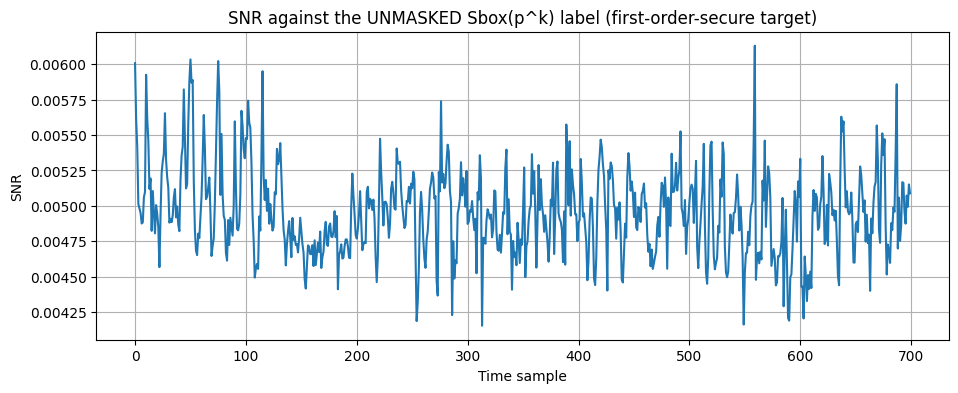

metadata['masks'] has 16 columns; scanning all single-column candidates for r_out ...
Per-column max SNR (sorted):
  col_0: max SNR = 6.2871
  col_15: max SNR = 0.7630
  col_14: max SNR = 0.0101
  col_13: max SNR = 0.0069
  col_1: max SNR = 0.0066
Unmasked-label SNR baseline (noise floor): 0.0061
Selected 'col_0' as r_out (max SNR 6.2871 >> baseline 0.0061). POI (leakage sample) = 517.
Max SNR vs. MASKED label: 6.2871 at sample 517 (a sharp, isolated peak confirms this is where Sbox(p^k) XOR r_out is physically manipulated)


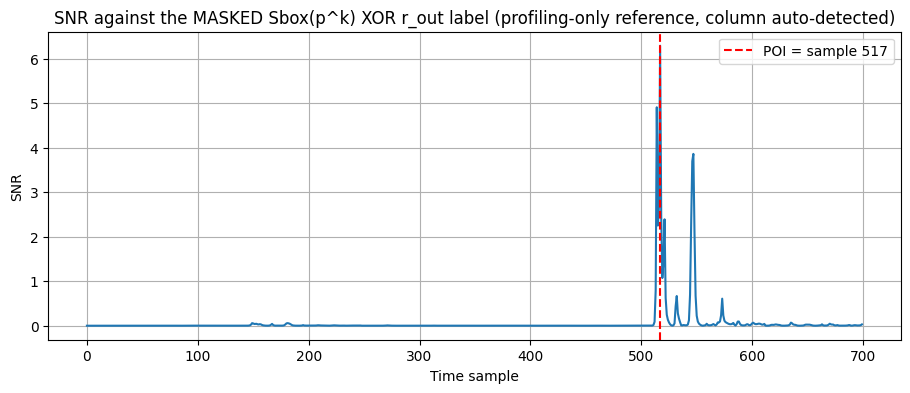

In [23]:
# SNR
def snr_curve(traces, labels, n_classes=256, min_count=5):
    n_samples = traces.shape[1]
    means = np.zeros((n_classes, n_samples))
    varis = np.zeros((n_classes, n_samples))
    valid = np.zeros(n_classes, dtype=bool)
    for c in range(n_classes):
        idx = labels == c
        if idx.sum() < min_count:
            continue
        means[c] = traces[idx].mean(axis=0)
        varis[c] = traces[idx].var(axis=0)
        valid[c] = True
    signal = means[valid].var(axis=0)
    noise = varis[valid].mean(axis=0)
    return signal / (noise + 1e-12)

snr_unmasked = snr_curve(X_profile, y_profile_unmasked)
print(f"Max SNR vs. UNMASKED label: {snr_unmasked.max():.4f} at sample {snr_unmasked.argmax()} "
      "(expect LOW/flat -> first-order masking holds)")

plt.figure()
plt.plot(snr_unmasked)
plt.title("SNR against the UNMASKED Sbox(p^k) label (first-order-secure target)")
plt.xlabel("Time sample"); plt.ylabel("SNR")
plt.show()

masked_profile = None
poi_sample = None
if D["masks_profile"] is not None:
    masks_arr = D["masks_profile"]
    n_mask_cols = masks_arr.shape[1]
    print(f"metadata['masks'] has {n_mask_cols} columns; scanning all single-column candidates for r_out ...")

    candidates = {}
    for j in range(n_mask_cols):
        cand_label = (y_profile_unmasked.astype(np.uint8) ^ masks_arr[:, j]).astype(np.int64)
        s = snr_curve(X_profile, cand_label)
        candidates[f"col_{j}"] = (s.max(), s)

    best_name = max(candidates, key=lambda k: candidates[k][0])
    best_max_snr, snr_masked = candidates[best_name]
    baseline = snr_unmasked.max()

    print("Per-column max SNR (sorted):")
    for name, (m, _) in sorted(candidates.items(), key=lambda kv: -kv[1][0])[:5]:
        print(f"  {name}: max SNR = {m:.4f}")
    print(f"Unmasked-label SNR baseline (noise floor): {baseline:.4f}")

    if best_max_snr > 5 * baseline:
        masked_profile_col = best_name
        poi_sample = int(snr_masked.argmax())
        masked_profile = True
        print(f"Selected '{masked_profile_col}' as r_out (max SNR {best_max_snr:.4f} >> baseline {baseline:.4f}). "
              f"POI (leakage sample) = {poi_sample}.")
    else:
        masked_profile = None
        poi_sample = int(snr_unmasked.argmax())
        print("WARNING: no mask column produced a clear SNR peak above the unmasked baseline. "
              "This dataset mirror may not expose a usable r_out, or the masking scheme combines masks "
              "across bytes differently than assumed. Falling back to the unmasked-SNR argmax as the POI "
              "estimate; the masked-SNR 'ground truth' plot below is skipped.")

if masked_profile is not None:
    print(f"Max SNR vs. MASKED label: {snr_masked.max():.4f} at sample {poi_sample} "
          "(a sharp, isolated peak confirms this is where Sbox(p^k) XOR r_out is physically manipulated)")
    plt.figure()
    plt.plot(snr_masked)
    plt.axvline(poi_sample, color="r", ls="--", label=f"POI = sample {poi_sample}")
    plt.title("SNR against the MASKED Sbox(p^k) XOR r_out label (profiling-only reference, column auto-detected)")
    plt.xlabel("Time sample"); plt.ylabel("SNR"); plt.legend()
    plt.show()

TVLA proxy groups -> fixed (pt[2]==195): 239 traces, random: 49761 traces


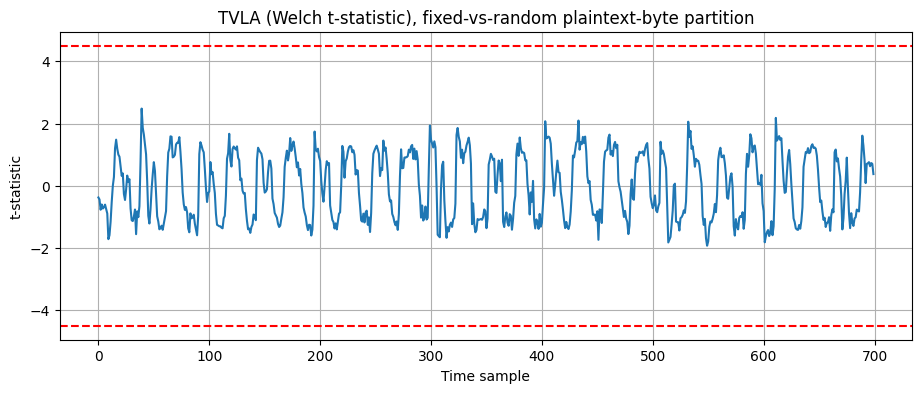

Samples exceeding |t| > 4.5: 0 / 700 (any sample above threshold = statistically significant, device-dependent leakage)


In [24]:
# TVLA (fixed vs random)
FIXED_BYTE_VALUE = int(D["pt_profile"][0, TARGET_BYTE])
fixed_mask = D["pt_profile"][:, TARGET_BYTE] == FIXED_BYTE_VALUE
random_mask = ~fixed_mask

print(f"TVLA proxy groups -> fixed (pt[{TARGET_BYTE}]=={FIXED_BYTE_VALUE}): {fixed_mask.sum()} traces, "
      f"random: {random_mask.sum()} traces")

t_stat, _ = ttest_ind(X_profile[fixed_mask], X_profile[random_mask], axis=0, equal_var=False)
THRESH = 4.5

plt.figure()
plt.plot(t_stat)
plt.axhline(THRESH, color="r", ls="--"); plt.axhline(-THRESH, color="r", ls="--")
plt.title("TVLA (Welch t-statistic), fixed-vs-random plaintext-byte partition")
plt.xlabel("Time sample"); plt.ylabel("t-statistic")
plt.show()

n_leaking = int((np.abs(t_stat) > THRESH).sum())
print(f"Samples exceeding |t| > {THRESH}: {n_leaking} / {len(t_stat)} "
      "(any sample above threshold = statistically significant, device-dependent leakage)")

## 2. Baseline attack: first-order CPA

Correlation power analysis (CPA) with a Hamming-weight model, run on the attack traces and aimed at the plain S-box output. This is the attack a lab would normally try first. If the masking holds, the correct key byte should not stand out from the 255 wrong guesses, no matter how many traces are used.

CPA result on ALL 10000 attack traces:
  True key byte 0xe0 rank among 256 hypotheses: 70 (0 would mean CPA recovered the key; any other value is a CPA FAILURE)
  Top-5 key hypotheses by max |correlation|: ['0x83', '0x93', '0xf3', '0x8', '0xc6']


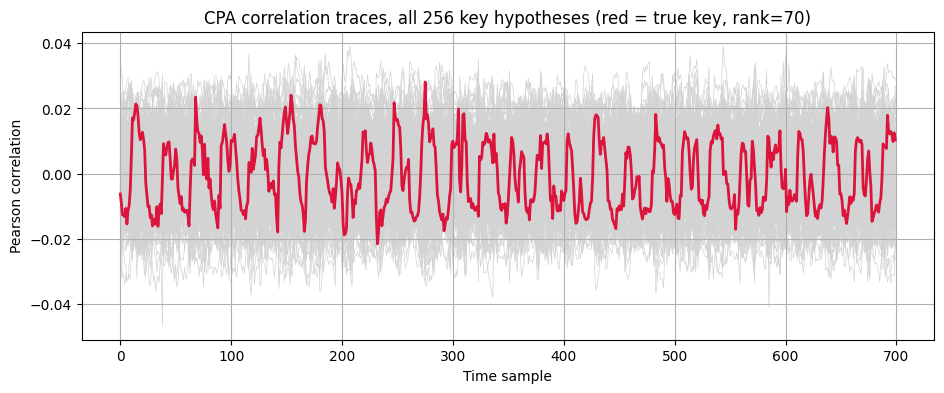

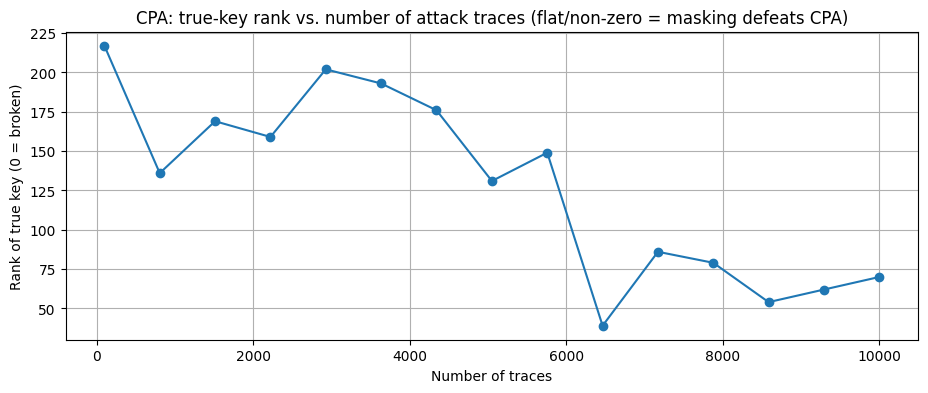

In [25]:
# CPA
def cpa_attack(traces, plaintext_col, n_traces=None):
    X = traces if n_traces is None else traces[:n_traces]
    pt = plaintext_col if n_traces is None else plaintext_col[:n_traces]
    Xc = X - X.mean(axis=0, keepdims=True)
    Xss = (Xc ** 2).sum(axis=0)
    best_abs_corr = np.zeros(256)
    corr_traces = np.zeros((256, X.shape[1]))
    for kh in range(256):
        hw = HW[sbox_out(pt, kh)]
        hwc = hw - hw.mean()
        num = (hwc[:, None] * Xc).sum(axis=0)
        den = np.sqrt((hwc ** 2).sum() * Xss) + 1e-12
        corr = num / den
        corr_traces[kh] = corr
        best_abs_corr[kh] = np.abs(corr).max()
    return best_abs_corr, corr_traces

best_abs_corr, corr_traces = cpa_attack(X_attack, D["pt_attack"][:, TARGET_BYTE])
cpa_rank = int((best_abs_corr > best_abs_corr[ATTACK_KEY_BYTE]).sum())
order = np.argsort(-best_abs_corr)
print(f"CPA result on ALL {X_attack.shape[0]} attack traces:")
print(f"  True key byte {hex(ATTACK_KEY_BYTE)} rank among 256 hypotheses: {cpa_rank} "
      "(0 would mean CPA recovered the key; any other value is a CPA FAILURE)")
print(f"  Top-5 key hypotheses by max |correlation|: {[hex(k) for k in order[:5]]}")

plt.figure()
for kh in range(256):
    c = "crimson" if kh == ATTACK_KEY_BYTE else "lightgray"
    lw = 2.0 if kh == ATTACK_KEY_BYTE else 0.5
    plt.plot(corr_traces[kh], color=c, linewidth=lw, zorder=(2 if kh == ATTACK_KEY_BYTE else 1))
plt.title(f"CPA correlation traces, all 256 key hypotheses (red = true key, rank={cpa_rank})")
plt.xlabel("Time sample"); plt.ylabel("Pearson correlation")
plt.show()

trace_counts = np.unique(np.linspace(100, X_attack.shape[0], 15).astype(int))
ranks_vs_n = []
for n in trace_counts:
    bac, _ = cpa_attack(X_attack, D["pt_attack"][:, TARGET_BYTE], n_traces=n)
    ranks_vs_n.append(int((bac > bac[ATTACK_KEY_BYTE]).sum()))

plt.figure()
plt.plot(trace_counts, ranks_vs_n, marker="o")
plt.title("CPA: true-key rank vs. number of attack traces (flat/non-zero = masking defeats CPA)")
plt.xlabel("Number of traces"); plt.ylabel("Rank of true key (0 = broken)")
plt.show()

## 3. Deep-learning attack: MLP and 1D CNN

Both networks are trained to predict the plain S-box output (256 classes) from the raw trace. Since no single sample reveals that value, a successful model has to combine at least two leakage points, one from the mask and one from the masked value. For that reason the networks see the whole 700-sample trace instead of only the point found in Stage 1. The profiling and attack sets are kept separate, and model selection uses profiling data only.

In [26]:
# Preprocessing
N_SAMPLES = X_profile.shape[1]
mu, sigma = X_profile.mean(axis=0, keepdims=True), X_profile.std(axis=0, keepdims=True) + 1e-8

def standardize(X):
    return (X - mu) / sigma

X_profile_std = standardize(X_profile).astype(np.float32)
X_attack_std = standardize(X_attack).astype(np.float32)

y_profile_cat = keras.utils.to_categorical(y_profile_unmasked, num_classes=256)

N_VAL = max(1000, int(0.1 * X_profile_std.shape[0]))
X_train, X_val = X_profile_std[:-N_VAL], X_profile_std[-N_VAL:]
y_train, y_val = y_profile_cat[:-N_VAL], y_profile_cat[-N_VAL:]
print("Train:", X_train.shape, " Val:", X_val.shape, " Attack:", X_attack_std.shape)

Train: (45000, 700)  Val: (5000, 700)  Attack: (10000, 700)


### Choosing the best epoch

Validation loss and accuracy are poor guides here. With 256 classes and a weak signal, the epoch with the lowest validation loss is often not the epoch that recovers the key best.

The profiling and attack sets use the same fixed key, so the last part of the profiling set can be held back and used to compute a real guessing entropy after every second epoch. The weights from the epoch with the lowest guessing entropy are kept. The attack set is never used for this choice.

In [27]:
# Validation guessing entropy callback
pt_val = D["pt_profile"][-N_VAL:, TARGET_BYTE]
PROFILE_KEY_BYTE = int(D["key_profile"][0, TARGET_BYTE])
assert PROFILE_KEY_BYTE == ATTACK_KEY_BYTE, (
    "Profiling and attack sets must share the fixed key for GE-based validation to be meaningful; "
    "if this fails, this .h5 is a variable-key ASCAD variant and val_loss-based selection must be used instead."
)

def quick_ge(probs, pt_col, true_key, n_repeats=15, max_traces=300, rng=None):
    rng = rng or np.random.default_rng(0)
    n = probs.shape[0]
    max_traces = min(max_traces, n)
    log_probs = np.log(probs + 1e-40)
    hyp_labels = np.stack([sbox_out(pt_col, kh) for kh in range(256)], axis=0)
    per_trace_ll = np.take_along_axis(log_probs, hyp_labels.T, axis=1)
    ge = np.zeros(max_traces)
    for _ in range(n_repeats):
        order = rng.permutation(n)[:max_traces]
        cum = np.cumsum(per_trace_ll[order], axis=0)
        ranks = (cum > cum[:, true_key][:, None]).sum(axis=1)
        ge += ranks
    return ge / n_repeats

class GuessingEntropyMonitor(keras.callbacks.Callback):
    def __init__(self, X_val, pt_val, true_key, every=1, max_traces=300, n_repeats=15, patience=15):
        super().__init__()
        self.X_val, self.pt_val, self.true_key = X_val, pt_val, true_key
        self.every, self.max_traces, self.n_repeats, self.patience = every, max_traces, n_repeats, patience
        self.best_ge_final = np.inf
        self.best_weights = None
        self.epochs_since_best = 0
        self.history = []

    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.every != 0:
            return
        probs = self.model.predict(self.X_val, verbose=0)
        ge = quick_ge(probs, self.pt_val, self.true_key, n_repeats=self.n_repeats, max_traces=self.max_traces)
        final_ge = float(ge[-1])
        self.history.append((epoch, final_ge))
        print(f"  [GE monitor] epoch {epoch + 1}: val GE @ {self.max_traces} traces = {final_ge:.2f}")
        if final_ge < self.best_ge_final - 1e-6:
            self.best_ge_final = final_ge
            self.best_weights = [w.copy() for w in self.model.get_weights()]
            self.epochs_since_best = 0
        else:
            self.epochs_since_best += 1
            if self.epochs_since_best >= self.patience:
                self.model.stop_training = True

    def on_train_end(self, logs=None):
        if self.best_weights is not None:
            self.model.set_weights(self.best_weights)
            print(f"  [GE monitor] restored weights from best validation GE = {self.best_ge_final:.2f}")

In [28]:
# MLP
def build_mlp(n_samples):
    model = keras.Sequential([
        layers.Input(shape=(n_samples,)),
        layers.Dense(200, activation="selu"),
        layers.Dense(200, activation="selu"),
        layers.Dense(200, activation="selu"),
        layers.Dense(200, activation="selu"),
        layers.Dense(200, activation="selu"),
        layers.Dense(200, activation="selu"),
        layers.Dense(256, activation="softmax"),
    ], name="mlp_baseline")
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    return model

mlp = build_mlp(N_SAMPLES)
mlp.summary()

ge_monitor_mlp = GuessingEntropyMonitor(X_val, pt_val, ATTACK_KEY_BYTE, every=2, patience=10)
history_mlp = mlp.fit(X_train, y_train, validation_data=(X_val, y_val),
                       epochs=75, batch_size=128, callbacks=[ge_monitor_mlp], verbose=2)

Model: "mlp_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 200)            │       140,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 200)            │        40,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 200)            │        40,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 200)            │        40,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 200)            │        40,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 200)            │        40,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 256)            │        51,456 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 392,656 (1.50 MB)

 Trainable params: 392,656 (1.50 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/75
352/352 - 4s - 13ms/step - accuracy: 0.0035 - loss: 5.7856 - val_accuracy: 0.0050 - val_loss: 5.6790
Epoch 2/75
  [GE monitor] epoch 2: val GE @ 300 traces = 133.27
352/352 - 3s - 9ms/step - accuracy: 0.0044 - loss: 5.6624 - val_accuracy: 0.0024 - val_loss: 5.6879
Epoch 3/75
352/352 - 3s - 8ms/step - accuracy: 0.0055 - loss: 5.6353 - val_accuracy: 0.0036 - val_loss: 5.7020
Epoch 4/75
  [GE monitor] epoch 4: val GE @ 300 traces = 29.93
352/352 - 3s - 9ms/step - accuracy: 0.0069 - loss: 5.6022 - val_accuracy: 0.0054 - val_loss: 5.6661
Epoch 5/75
352/352 - 3s - 7ms/step - accuracy: 0.0084 - loss: 5.5472 - val_accuracy: 0.0054 - val_loss: 5.6430
Epoch 6/75
  [GE monitor] epoch 6: val GE @ 300 traces = 16.60
352/352 - 3s - 9ms/step - accuracy: 0.0100 - loss: 5.4842 - val_accuracy: 0.0058 - val_loss: 5.6294
Epoch 7/75
352/352 - 3s - 8ms/step - accuracy: 0.0129 - loss: 5.4230 - val_accuracy: 0.0070 - val_loss: 5.6351
Epoch 8/75
  [GE monitor] epoch 8: val GE @ 300 traces = 6.53
352

In [29]:
# 1D CNN
def build_cnn(n_samples):
    inp = layers.Input(shape=(n_samples, 1))
    x = inp
    for filters, kernel in [(8, 11), (16, 11), (32, 11)]:
        x = layers.Conv1D(filters, kernel, padding="same", activation="selu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.AveragePooling1D(2)(x)
    x = layers.Flatten()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation="selu")(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation="selu")(x)
    out = layers.Dense(256, activation="softmax")(x)
    model = keras.Model(inp, out, name="cnn_1d")
    model.compile(optimizer=keras.optimizers.Adam(1e-4),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    return model

cnn = build_cnn(N_SAMPLES)
cnn.summary()

X_train_cnn = X_train[..., None]
X_val_cnn = X_val[..., None]
X_attack_cnn = X_attack_std[..., None]

ge_monitor_cnn = GuessingEntropyMonitor(X_val_cnn, pt_val, ATTACK_KEY_BYTE, every=2, patience=10)
history_cnn = cnn.fit(X_train_cnn, y_train, validation_data=(X_val_cnn, y_val),
                       epochs=75, batch_size=128, callbacks=[ge_monitor_cnn], verbose=2)

Model: "cnn_1d"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 700, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 700, 8)         │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 700, 8)         │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling1d_3             │ (None, 350, 8)         │             0 │
│ (AveragePooling1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 350, 16)        │         1,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 350, 16)        │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling1d_4             │ (None, 175, 16)        │             0 │
│ (AveragePooling1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 175, 32)        │         5,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 175, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling1d_5             │ (None, 87, 32)         │             0 │
│ (AveragePooling1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2784)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2784)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 128)            │       356,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 256)            │        33,024 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 413,424 (1.58 MB)

 Trainable params: 413,312 (1.58 MB)

 Non-trainable params: 112 (448.00 B)

Epoch 1/75
352/352 - 18s - 52ms/step - accuracy: 0.0038 - loss: 5.8910 - val_accuracy: 0.0038 - val_loss: 5.6489
Epoch 2/75
  [GE monitor] epoch 2: val GE @ 300 traces = 157.27
352/352 - 17s - 48ms/step - accuracy: 0.0045 - loss: 5.7457 - val_accuracy: 0.0048 - val_loss: 5.6200
Epoch 3/75
352/352 - 16s - 45ms/step - accuracy: 0.0048 - loss: 5.6642 - val_accuracy: 0.0030 - val_loss: 5.6024
Epoch 4/75
  [GE monitor] epoch 4: val GE @ 300 traces = 150.00
352/352 - 17s - 49ms/step - accuracy: 0.0049 - loss: 5.6159 - val_accuracy: 0.0032 - val_loss: 5.5877
Epoch 5/75
352/352 - 16s - 46ms/step - accuracy: 0.0052 - loss: 5.5889 - val_accuracy: 0.0042 - val_loss: 5.5851
Epoch 6/75
  [GE monitor] epoch 6: val GE @ 300 traces = 155.40
352/352 - 17s - 50ms/step - accuracy: 0.0052 - loss: 5.5698 - val_accuracy: 0.0034 - val_loss: 5.5816
Epoch 7/75
352/352 - 17s - 48ms/step - accuracy: 0.0060 - loss: 5.5532 - val_accuracy: 0.0038 - val_loss: 5.5822
Epoch 8/75
  [GE monitor] epoch 8: val GE @ 300 tr

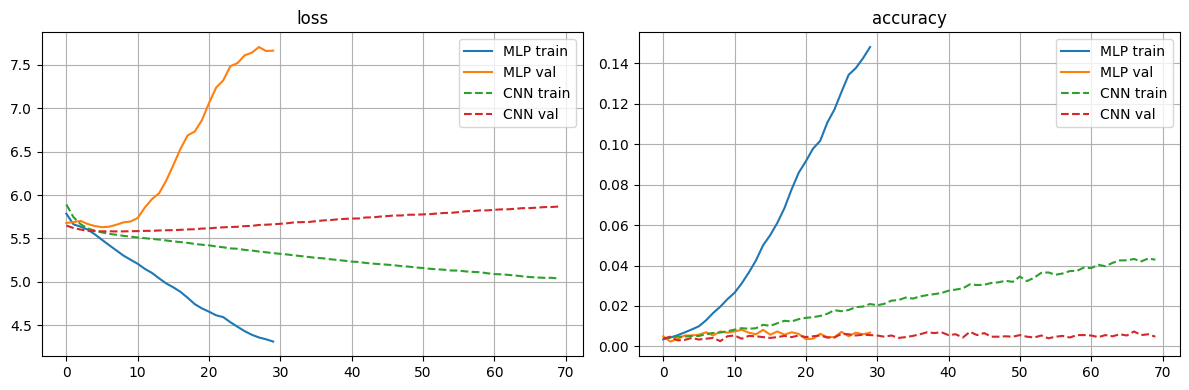

Reminder: top-1 accuracy over 256 classes is near-random even for a model that fully breaks the key once its per-trace log-likelihoods are combined across many traces -- see Stage 4.


In [30]:
# Training curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(history_mlp.history[metric], label="MLP train")
    ax.plot(history_mlp.history[f"val_{metric}"], label="MLP val")
    ax.plot(history_cnn.history[metric], label="CNN train", ls="--")
    ax.plot(history_cnn.history[f"val_{metric}"], label="CNN val", ls="--")
    ax.set_title(metric); ax.legend()
plt.tight_layout(); plt.show()
print("Reminder: top-1 accuracy over 256 classes is near-random even for a model that fully breaks the key once "
      "its per-trace log-likelihoods are combined across many traces -- see Stage 4.")

## 4. Guessing entropy and minimum traces to disclosure (MTD)

For each attack trace, the network gives a probability for every S-box output class. For a key guess, the probability of the class `Sbox(p ^ guess)` is turned into a log-likelihood and added up over the traces.

**Guessing entropy** at `n` traces is the average rank of the true key byte after `n` traces, taken over many random orderings of the traces. A value of 0 means the key is ranked first. **MTD** is the smallest `n` from which the guessing entropy stays at 0.

MLP  MTD (traces to GE=0, sustained): 2946
CNN  MTD (traces to GE=0, sustained): None


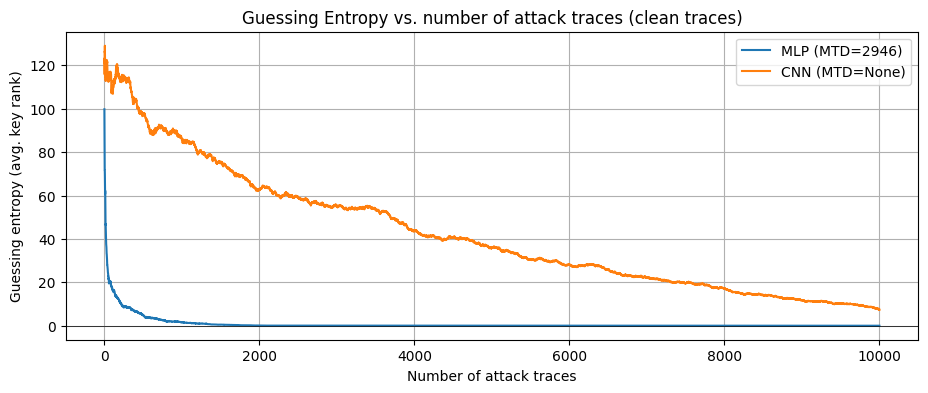

In [31]:
# Guessing entropy and MTD
def guessing_entropy(probs, plaintext_col, true_key_byte, n_repeats=100, max_traces=None, rng=None):
    rng = rng or np.random.default_rng(0)
    n = probs.shape[0]
    max_traces = max_traces or n
    log_probs = np.log(probs + 1e-40)
    hyp_labels = np.stack([sbox_out(plaintext_col, kh) for kh in range(256)], axis=0)
    per_trace_ll = np.take_along_axis(log_probs, hyp_labels.T, axis=1)

    ge = np.zeros(max_traces)
    for _ in range(n_repeats):
        order = rng.permutation(n)[:max_traces]
        cum = np.cumsum(per_trace_ll[order], axis=0)
        true_ll = cum[:, true_key_byte][:, None]
        ranks = (cum > true_ll).sum(axis=1)
        ge += ranks
    ge /= n_repeats
    return ge

def mtd_from_ge(ge, patience=20):
    zero = ge == 0
    for i in range(len(zero) - patience):
        if zero[i:i + patience].all():
            return i + 1
    return None

N_ATTACK_EVAL = X_attack_std.shape[0]
probs_mlp = mlp.predict(X_attack_std[:N_ATTACK_EVAL], verbose=0)
probs_cnn = cnn.predict(X_attack_cnn[:N_ATTACK_EVAL], verbose=0)
pt_eval = D["pt_attack"][:N_ATTACK_EVAL, TARGET_BYTE]

ge_mlp = guessing_entropy(probs_mlp, pt_eval, ATTACK_KEY_BYTE, n_repeats=100)
ge_cnn = guessing_entropy(probs_cnn, pt_eval, ATTACK_KEY_BYTE, n_repeats=100)
mtd_mlp, mtd_cnn = mtd_from_ge(ge_mlp), mtd_from_ge(ge_cnn)

print(f"MLP  MTD (traces to GE=0, sustained): {mtd_mlp}")
print(f"CNN  MTD (traces to GE=0, sustained): {mtd_cnn}")

plt.figure()
plt.plot(np.arange(1, len(ge_mlp) + 1), ge_mlp, label=f"MLP (MTD={mtd_mlp})")
plt.plot(np.arange(1, len(ge_cnn) + 1), ge_cnn, label=f"CNN (MTD={mtd_cnn})")
plt.axhline(0, color="k", lw=0.5)
plt.title("Guessing Entropy vs. number of attack traces (clean traces)")
plt.xlabel("Number of attack traces"); plt.ylabel("Guessing entropy (avg. key rank)")
plt.legend(); plt.show()

## 5. Stress test with jitter and noise, and saliency

Real chips often add clock jitter, random delays or noise on top of masking. Both are simulated here on the attack traces, one at a time, and the MTD is measured again for both models. The notebook ends with an input-gradient saliency plot, to see whether the CNN pays attention to the sample found in Stage 1.

In [32]:
# Jitter and noise simulation
def apply_jitter(X, max_shift, rng):
    out = np.empty_like(X)
    shifts = rng.integers(-max_shift, max_shift + 1, size=X.shape[0])
    for i, s in enumerate(shifts):
        out[i] = np.roll(X[i], s)
    return out

def apply_noise(X, sigma, rng):
    return X + rng.normal(0, sigma, size=X.shape).astype(X.dtype)

rng = np.random.default_rng(SEED)
conditions = {
    "clean":        lambda X: X,
    "jitter_±5":    lambda X: apply_jitter(X, 5, rng),
    "jitter_±10":   lambda X: apply_jitter(X, 10, rng),
    "jitter_±20":   lambda X: apply_jitter(X, 20, rng),
    "noise_σ=1.0":  lambda X: apply_noise(X, 1.0, rng),
    "noise_σ=2.0":  lambda X: apply_noise(X, 2.0, rng),
}

results = {}
X_eval_raw = X_attack[:N_ATTACK_EVAL]
for name, fn in conditions.items():
    X_pert = fn(X_eval_raw.copy())
    X_pert_std = standardize(X_pert).astype(np.float32)

    p_mlp = mlp.predict(X_pert_std, verbose=0)
    p_cnn = cnn.predict(X_pert_std[..., None], verbose=0)

    ge_m = guessing_entropy(p_mlp, pt_eval, ATTACK_KEY_BYTE, n_repeats=50)
    ge_c = guessing_entropy(p_cnn, pt_eval, ATTACK_KEY_BYTE, n_repeats=50)
    results[name] = {
        "mtd_mlp": mtd_from_ge(ge_m), "mtd_cnn": mtd_from_ge(ge_c),
        "ge_mlp": ge_m, "ge_cnn": ge_c,
    }
    print(f"{name:12s} -> MTD(MLP)={results[name]['mtd_mlp']}, MTD(CNN)={results[name]['mtd_cnn']}")

clean        -> MTD(MLP)=2135, MTD(CNN)=None
jitter_±5    -> MTD(MLP)=None, MTD(CNN)=None
jitter_±10   -> MTD(MLP)=None, MTD(CNN)=None
jitter_±20   -> MTD(MLP)=None, MTD(CNN)=None
noise_σ=1.0  -> MTD(MLP)=2448, MTD(CNN)=None
noise_σ=2.0  -> MTD(MLP)=2926, MTD(CNN)=None


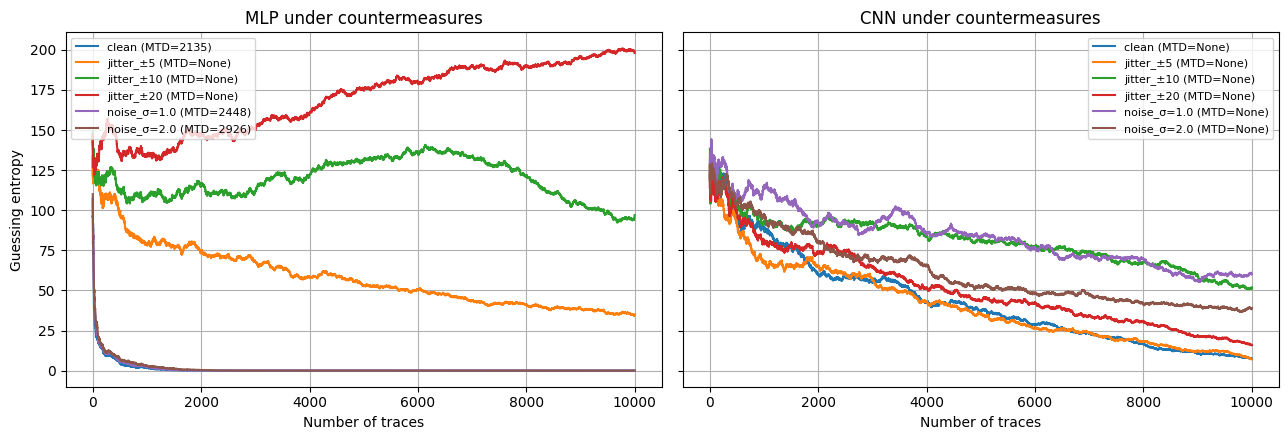

{
  "clean": {
    "MLP": 2135,
    "CNN": null
  },
  "jitter_\u00b15": {
    "MLP": null,
    "CNN": null
  },
  "jitter_\u00b110": {
    "MLP": null,
    "CNN": null
  },
  "jitter_\u00b120": {
    "MLP": null,
    "CNN": null
  },
  "noise_\u03c3=1.0": {
    "MLP": 2448,
    "CNN": null
  },
  "noise_\u03c3=2.0": {
    "MLP": 2926,
    "CNN": null
  }
}


In [33]:
# Countermeasure plots
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
model_panels = [("ge_mlp", "mtd_mlp", "MLP under countermeasures"),
                 ("ge_cnn", "mtd_cnn", "CNN under countermeasures")]
for ax, (ge_key, mtd_key, title) in zip(axes, model_panels):
    for name, r in results.items():
        label = f"{name} (MTD={r[mtd_key]})"
        ax.plot(r[ge_key], label=label)
    ax.set_title(title); ax.set_xlabel("Number of traces"); ax.legend(fontsize=8)
axes[0].set_ylabel("Guessing entropy")
plt.tight_layout(); plt.show()

mtd_table = {name: {"MLP": r["mtd_mlp"], "CNN": r["mtd_cnn"]} for name, r in results.items()}
print(json.dumps(mtd_table, indent=2))

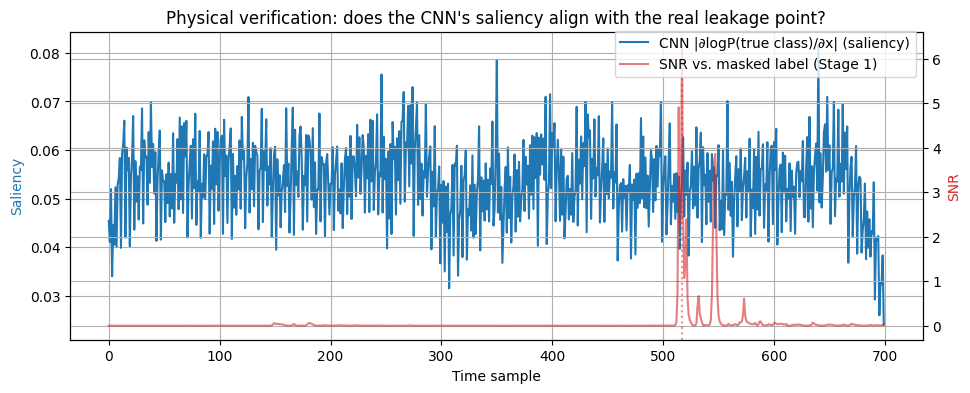

Saliency peak at sample 640; Stage-1 SNR POI at sample 517. Distance: 123 samples.


In [34]:
# Saliency
def input_gradient_saliency(model, X, true_labels, n_samples_eval=500):
    Xs = tf.convert_to_tensor(X[:n_samples_eval])
    y_idx = tf.cast(true_labels[:n_samples_eval], tf.int32)
    with tf.GradientTape() as tape:
        tape.watch(Xs)
        preds = model(Xs, training=False)
        logp = tf.math.log(tf.gather(preds, y_idx, axis=1, batch_dims=1) + 1e-12)
        loss = tf.reduce_sum(logp)
    grads = tape.gradient(loss, Xs).numpy()
    return np.mean(np.abs(grads), axis=0).reshape(-1)

y_attack_unmasked_eval = sbox_out(pt_eval, ATTACK_KEY_BYTE)
saliency_cnn = input_gradient_saliency(cnn, X_attack_cnn[:N_ATTACK_EVAL], y_attack_unmasked_eval)

fig, ax1 = plt.subplots()
ax1.plot(saliency_cnn, color="tab:blue", label="CNN |∂logP(true class)/∂x| (saliency)")
ax1.set_xlabel("Time sample"); ax1.set_ylabel("Saliency", color="tab:blue")
ax2 = ax1.twinx()
if masked_profile is not None:
    ax2.plot(snr_masked, color="tab:red", alpha=0.6, label="SNR vs. masked label (Stage 1)")
    ax2.axvline(poi_sample, color="tab:red", ls=":", alpha=0.5)
ax2.set_ylabel("SNR", color="tab:red")
plt.title("Physical verification: does the CNN's saliency align with the real leakage point?")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.9))
plt.show()

top_saliency_sample = int(np.argmax(saliency_cnn))
print(f"Saliency peak at sample {top_saliency_sample}; Stage-1 SNR POI at sample {poi_sample}. "
      f"Distance: {abs(top_saliency_sample - poi_sample)} samples.")

## 6. Summary

| Stage | Method | Result |
|---|---|---|
| 1 | SNR and TVLA | Plain S-box output does not leak (max SNR 0.0061). The masked value leaks clearly at sample 517 (SNR 6.29). TVLA proxy test finds no sample above the 4.5 threshold. |
| 2 | CPA | Fails. The true key byte `0xe0` ranks 70th out of 256 after all 10,000 attack traces. |
| 3 | MLP and 1D CNN | MLP overfits quickly, but the epoch chosen by guessing entropy still generalises. The CNN learns very slowly and barely beats chance. |
| 4 | Guessing entropy and MTD | MLP: MTD of 2,946 traces. CNN: no MTD within 10,000 traces (guessing entropy ends near 8). |
| 5 | Jitter, noise, saliency | Jitter of ±5 samples or more stops the MLP attack. Noise (σ = 1 and 2) only raises the MLP MTD moderately. The CNN never reaches an MTD. CNN saliency peaks at sample 640, 123 samples away from the Stage 1 leakage point. |

**Takeaways.** Masking alone stops the classical attack (CPA), but a simple MLP trained on profiling data still recovers the key byte in a few thousand traces. Small amounts of desynchronisation protect much better than added noise. The CNN, as built here, did not work and would need a different design or tuning. The saliency result does not show that it focuses on the real leakage point.

The MLP MTD is 2,946 in Stage 4 and 2,135 for the clean case in Stage 5. Both come from the same model, but they average over a different number of random trace orderings (100 and 50), which is the likely reason for the difference.